## Imports

In [62]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Libraries imported successfully!")

Libraries imported successfully!


In [63]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Selected device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not available. Using CPU.")

Selected device: cuda
GPU: Tesla T4


## Load Dataset

In [64]:
from pathlib import Path

for file in Path("/content/Data").rglob("cardio_train.csv"):
    print(file)

/content/Data/cardio_train.csv


In [65]:
DATA_PATH = "/content/Data/cardio_train.csv"

df = pd.read_csv(DATA_PATH, sep=";")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (70000, 13)


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0


##Verifiy Dataset

In [66]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nDataset information:")
df.info()

Number of rows: 70000
Number of columns: 13

Column names:
['id', 'age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio']

Data types:
id               int64
age              int64
gender           int64
height           int64
weight         float64
ap_hi            int64
ap_lo            int64
cholesterol      int64
gluc             int64
smoke            int64
alco             int64
active           int64
cardio           int64
dtype: object

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           70000 non-null  int64  
 1   age          70000 non-null  int64  
 2   gender       70000 non-null  int64  
 3   height       70000 non-null  int64  
 4   weight       70000 non-null  float64
 5   ap_hi        70000 non-null  int64  
 6   ap_lo        70000 no

In [67]:
expected_columns = [
    "id", "age", "gender", "height", "weight",
    "ap_hi", "ap_lo", "cholesterol", "gluc",
    "smoke", "alco", "active", "cardio"
]

assert df.shape[1] == 13, "Unexpected number of columns!"
assert df.columns.tolist() == expected_columns, "Unexpected column structure!"
assert df.shape[0] == 70000, "Unexpected number of records!"
assert df["cardio"].isin([0, 1]).all(), "Invalid target values!"

print("All initial dataset checks passed!")

All initial dataset checks passed!


## EDA

In [68]:
# Basic dataset information
print("Dataset Shape:", df.shape)

print("\nData Types:")
print(df.dtypes)

print("\nStatistical Summary:")
display(df.describe().T)

Dataset Shape: (70000, 13)

Data Types:
id               int64
age              int64
gender           int64
height           int64
weight         float64
ap_hi            int64
ap_lo            int64
cholesterol      int64
gluc             int64
smoke            int64
alco             int64
active           int64
cardio           int64
dtype: object

Statistical Summary:


,count,mean,std,min,25%,50%,75%,max
id,70000.0,49972.419900,28851.302323,0.0,25006.75,50001.5,74889.25,99999.0
age,70000.0,19468.865814,2467.251667,10798.0,17664.00,19703.0,21327.00,23713.0
gender,70000.0,1.349571,0.476838,1.0,1.00,1.0,2.00,2.0
height,70000.0,164.359229,8.210126,55.0,159.00,165.0,170.00,250.0
weight,70000.0,74.205690,14.395757,10.0,65.00,72.0,82.00,200.0
ap_hi,70000.0,128.817286,154.011419,-150.0,120.00,120.0,140.00,16020.0
ap_lo,70000.0,96.630414,188.472530,-70.0,80.00,80.0,90.00,11000.0
cholesterol,70000.0,1.366871,0.680250,1.0,1.00,1.0,2.00,3.0
gluc,70000.0,1.226457,0.572270,1.0,1.00,1.0,1.00,3.0
smoke,70000.0,0.088129,0.283484,0.0,0.00,0.0,0.00,1.0


In [69]:
missing_values = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().sum() / len(df)) * 100
})

display(missing_values)

,Missing Count,Missing Percentage
id,0,0.0
age,0,0.0
gender,0,0.0
height,0,0.0
weight,0,0.0
ap_hi,0,0.0
ap_lo,0,0.0
cholesterol,0,0.0
gluc,0,0.0
smoke,0,0.0


In [70]:
# Exact duplicate rows
exact_duplicates = df.duplicated().sum()

# Duplicate patient features, excluding ID
feature_columns = [col for col in df.columns if col != "id"]

duplicate_features = df.duplicated(
    subset=feature_columns,
    keep=False
).sum()

# Check identical features with conflicting cardio labels
label_conflicts = (
    df.groupby(feature_columns)["cardio"]
    .nunique()
)

conflicting_groups = (label_conflicts > 1).sum()

print("Exact duplicate rows:", exact_duplicates)
print("Rows involved in duplicate feature combinations:", duplicate_features)
print("Conflicting target groups:", conflicting_groups)

Exact duplicate rows: 0
Rows involved in duplicate feature combinations: 48
Conflicting target groups: 0


Class Counts:
cardio
0    35021
1    34979
Name: count, dtype: int64

Class Percentages:
cardio
0    50.03
1    49.97
Name: proportion, dtype: float64


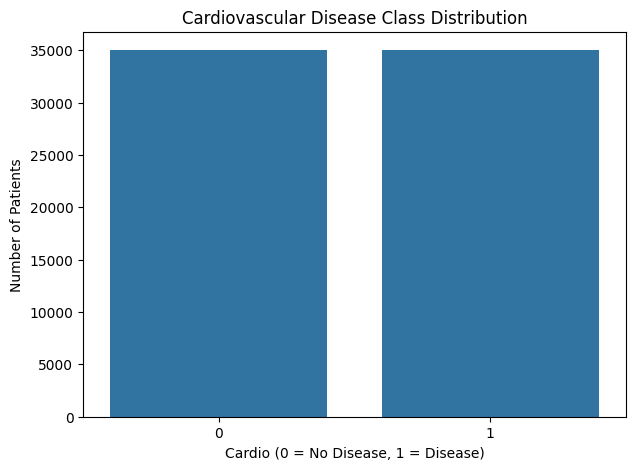

In [71]:
target_counts = df["cardio"].value_counts().sort_index()

target_percentages = df["cardio"].value_counts(
    normalize=True
).sort_index() * 100

print("Class Counts:")
print(target_counts)

print("\nClass Percentages:")
print(target_percentages)

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="cardio")

plt.title("Cardiovascular Disease Class Distribution")
plt.xlabel("Cardio (0 = No Disease, 1 = Disease)")
plt.ylabel("Number of Patients")

plt.show()

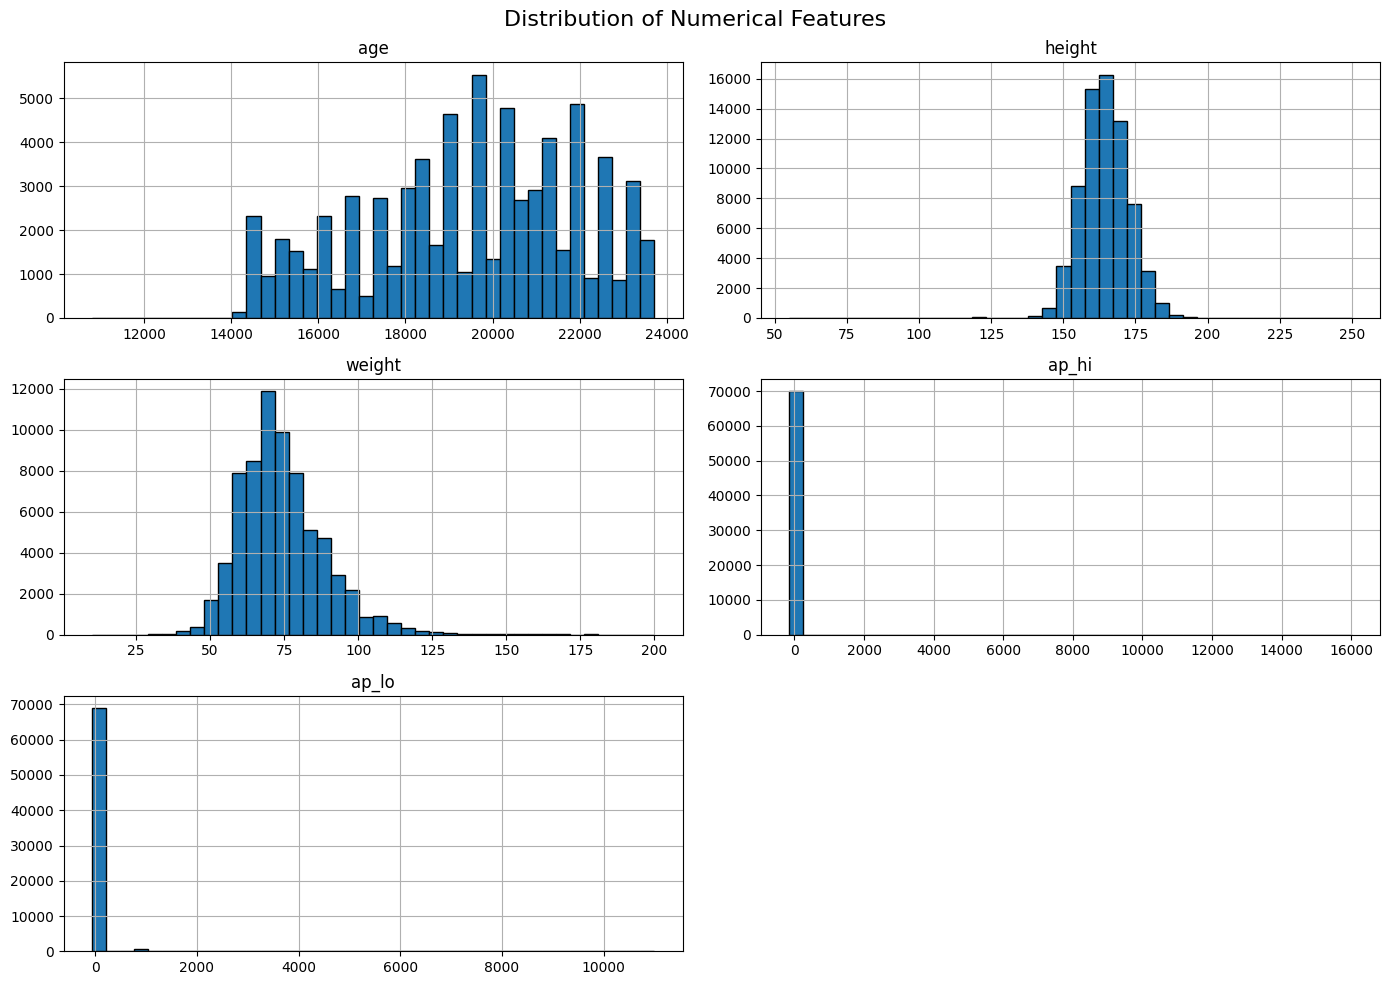

In [72]:
numerical_features = [
    "age", "height", "weight", "ap_hi", "ap_lo"
]

df[numerical_features].hist(
    figsize=(14, 10),
    bins=40,
    edgecolor="black"
)

plt.suptitle("Distribution of Numerical Features", fontsize=16)
plt.tight_layout()
plt.show()

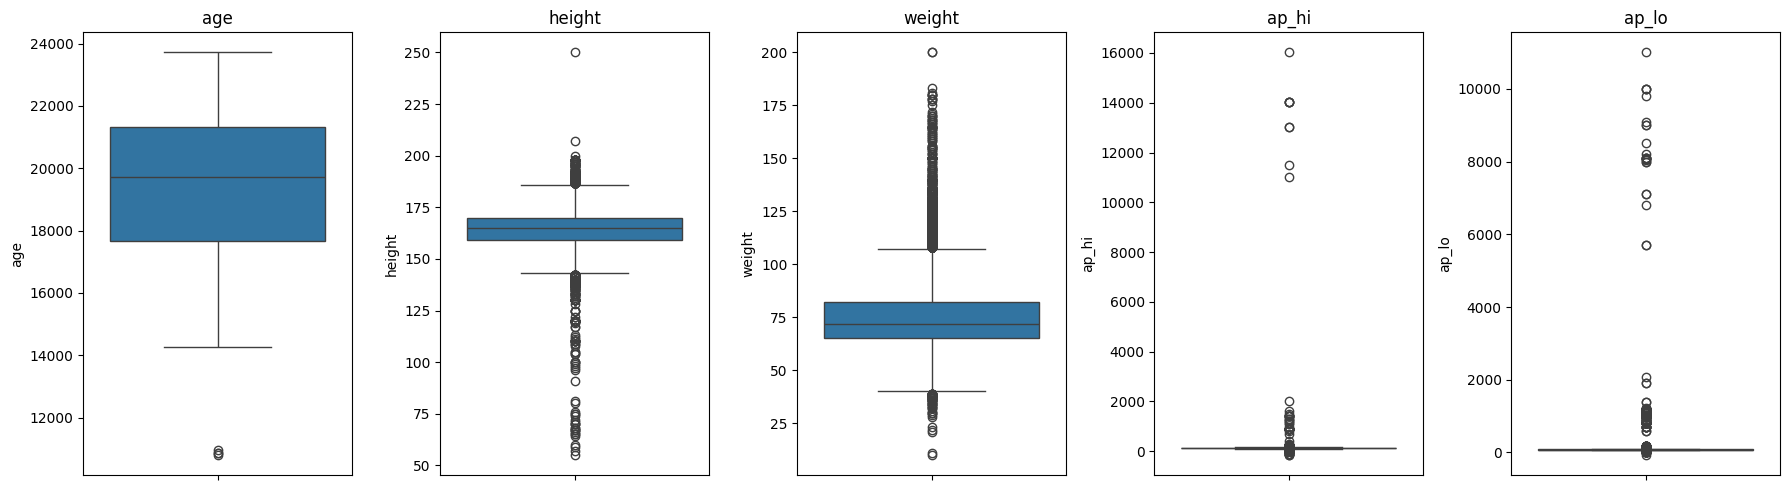

In [73]:
fig, axes = plt.subplots(1, 5, figsize=(18, 5))

for i, feature in enumerate(numerical_features):
    sns.boxplot(y=df[feature], ax=axes[i])
    axes[i].set_title(feature)

plt.tight_layout()
plt.show()

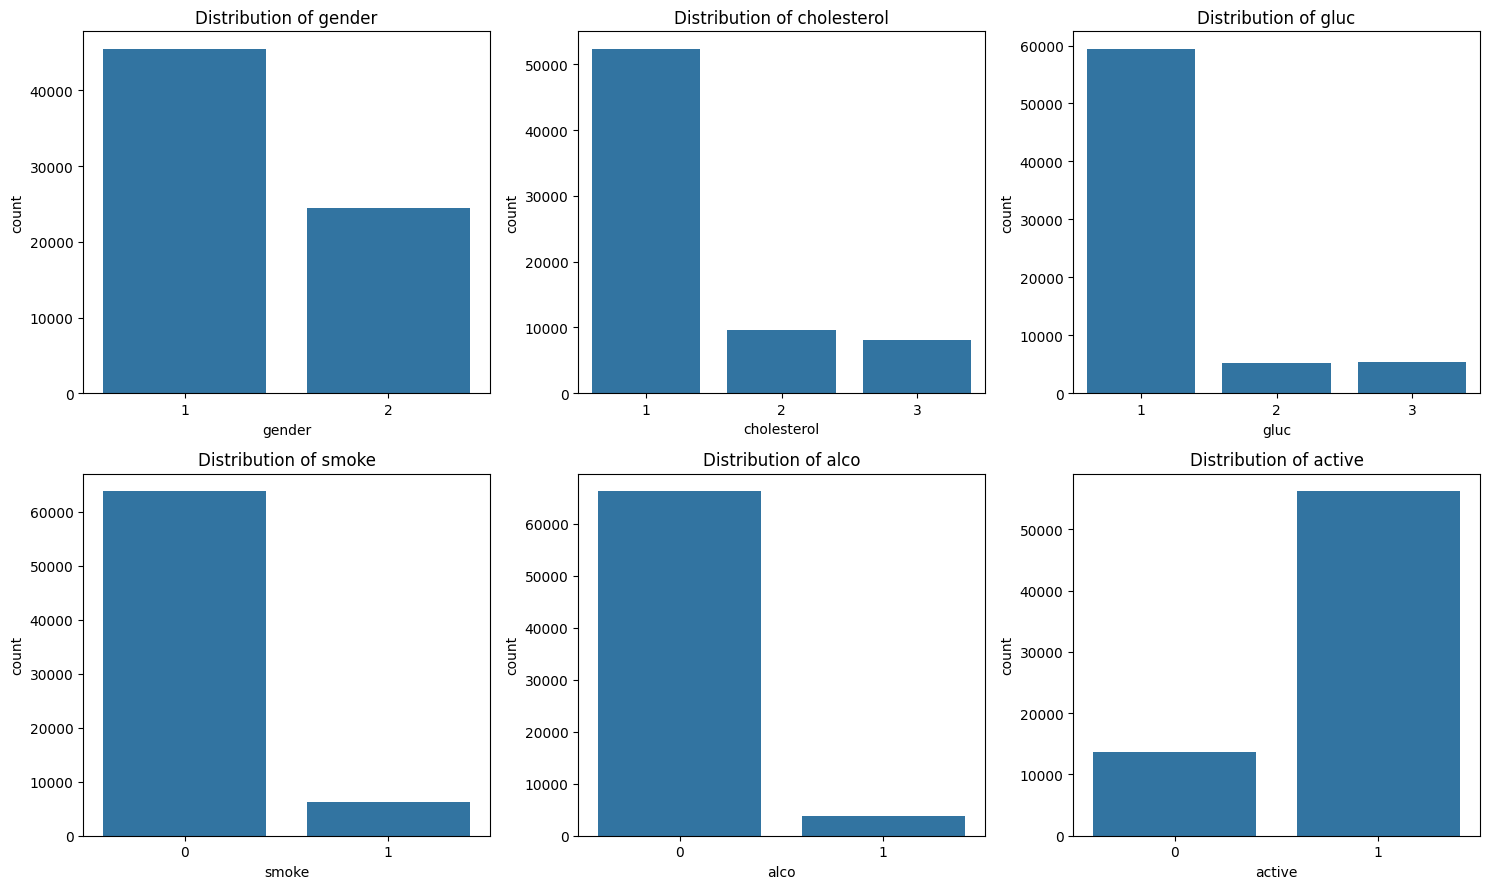

In [74]:
categorical_features = [
    "gender",
    "cholesterol",
    "gluc",
    "smoke",
    "alco",
    "active"
]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for feature, ax in zip(categorical_features, axes.flatten()):
    sns.countplot(data=df, x=feature, ax=ax)
    ax.set_title(f"Distribution of {feature}")

plt.tight_layout()
plt.show()

In [75]:
for feature in categorical_features + ["cardio"]:
    print(f"\n{feature}:")
    print(sorted(df[feature].dropna().unique()))


gender:
[np.int64(1), np.int64(2)]

cholesterol:
[np.int64(1), np.int64(2), np.int64(3)]

gluc:
[np.int64(1), np.int64(2), np.int64(3)]

smoke:
[np.int64(0), np.int64(1)]

alco:
[np.int64(0), np.int64(1)]

active:
[np.int64(0), np.int64(1)]

cardio:
[np.int64(0), np.int64(1)]


In [76]:
print("Systolic BP (ap_hi):")
print(df["ap_hi"].describe())

print("\nDiastolic BP (ap_lo):")
print(df["ap_lo"].describe())

# Basic logical checks
print("\nInvalid or suspicious measurements:")

print("Systolic <= 0:", (df["ap_hi"] <= 0).sum())
print("Diastolic <= 0:", (df["ap_lo"] <= 0).sum())

print("Systolic < Diastolic:",
      (df["ap_hi"] < df["ap_lo"]).sum())

print("Systolic == Diastolic:",
      (df["ap_hi"] == df["ap_lo"]).sum())

Systolic BP (ap_hi):
count    70000.000000
mean       128.817286
std        154.011419
min       -150.000000
25%        120.000000
50%        120.000000
75%        140.000000
max      16020.000000
Name: ap_hi, dtype: float64

Diastolic BP (ap_lo):
count    70000.000000
mean        96.630414
std        188.472530
min        -70.000000
25%         80.000000
50%         80.000000
75%         90.000000
max      11000.000000
Name: ap_lo, dtype: float64

Invalid or suspicious measurements:
Systolic <= 0: 7
Diastolic <= 0: 22
Systolic < Diastolic: 1234
Systolic == Diastolic: 2


In [77]:
print("Lowest systolic readings:")
display(df.nsmallest(15, "ap_hi")[
    ["age", "gender", "height", "weight", "ap_hi", "ap_lo", "cardio"]
])

print("Highest systolic readings:")
display(df.nlargest(15, "ap_hi")[
    ["age", "gender", "height", "weight", "ap_hi", "ap_lo", "cardio"]
])

print("Lowest diastolic readings:")
display(df.nsmallest(15, "ap_lo")[
    ["age", "gender", "height", "weight", "ap_hi", "ap_lo", "cardio"]
])

print("Highest diastolic readings:")
display(df.nlargest(15, "ap_lo")[
    ["age", "gender", "height", "weight", "ap_hi", "ap_lo", "cardio"]
])

Lowest systolic readings:


,age,gender,height,weight,ap_hi,ap_lo,cardio
35040,23325,2,168,59.0,-150,80,1
23988,18301,1,162,74.0,-140,90,1
25240,14711,2,168,50.0,-120,80,1
46627,23646,2,160,59.0,-120,80,0
16021,22108,2,161,90.0,-115,70,0
4607,15281,1,165,78.0,-100,80,0
20536,15581,1,153,54.0,-100,70,0
8757,16905,2,163,63.0,1,2088,0
42334,18716,1,171,80.0,1,1088,1
5382,21240,1,162,69.0,7,80,0


Highest systolic readings:


,age,gender,height,weight,ap_hi,ap_lo,cardio
40852,17438,1,169,70.0,16020,80,1
25464,15835,2,169,75.0,14020,80,1
25519,21361,1,169,71.0,14020,80,1
46912,16910,2,180,78.0,14020,90,1
47253,19731,1,160,65.0,14020,90,0
55459,18307,1,152,76.0,13010,80,1
55847,23182,1,161,105.0,13010,80,0
7763,21032,1,175,80.0,11500,90,1
51438,18784,2,168,65.0,11020,80,1
69370,14696,1,170,74.0,2000,100,1


Lowest diastolic readings:


,age,gender,height,weight,ap_hi,ap_lo,cardio
60106,22571,1,167,74.0,15,-70,1
2014,22712,2,167,59.0,906,0,0
13489,14965,2,150,60.0,130,0,0
16459,20457,1,156,50.0,138,0,1
17381,18226,1,164,78.0,138,0,0
22923,21182,2,166,68.0,149,0,1
23867,16131,1,161,92.0,906,0,1
25454,17952,2,176,73.0,12,0,0
27686,23396,2,180,73.0,140,0,1
31783,16070,1,170,64.0,907,0,0


Highest diastolic readings:


,age,gender,height,weight,ap_hi,ap_lo,cardio
43326,23221,1,160,105.0,200,11000,1
2381,20994,2,186,105.0,140,10000,1
23849,18102,2,169,86.0,150,10000,1
68538,19062,1,166,70.0,160,10000,1
43434,21906,2,179,62.0,130,9800,0
6653,19528,1,162,69.0,130,9100,1
12086,21466,2,169,78.0,130,9011,1
32920,18335,1,156,65.0,150,9011,1
15990,14508,2,179,70.0,120,8500,0
44042,21220,1,165,74.0,120,8200,0


In [78]:
print("Lowest heights:")
display(df.nsmallest(15, "height"))

print("\nHighest heights:")
display(df.nlargest(15, "height"))

print("\nLowest weights:")
display(df.nsmallest(15, "weight"))

print("\nHighest weights:")
display(df.nlargest(15, "weight"))

Lowest heights:


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
22723,32456,23386,1,55,81.0,130,90,1,1,0,0,1,1
66643,95141,18830,1,57,61.0,130,90,1,1,0,0,1,1
64115,91523,18426,1,59,57.6,125,67,1,1,0,0,0,0
29157,41661,19088,1,60,69.0,110,70,1,1,0,0,0,0
27603,39462,20978,1,64,61.0,130,70,1,1,0,0,1,0
33607,48009,19709,2,65,72.0,130,80,1,1,0,0,0,0
44490,63545,19120,1,65,60.0,120,80,1,1,0,0,1,0
64454,92008,21348,1,66,63.0,12,80,1,1,0,0,0,1
14323,20459,22005,1,67,57.0,120,90,1,1,0,0,1,1
50789,72476,14499,2,67,60.0,110,80,1,1,1,1,1,0



Highest heights:


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
6486,9223,21220,1,250,86.0,140,100,3,1,0,0,1,1
21628,30894,19054,2,207,78.0,100,70,1,1,0,1,1,0
41901,59847,19187,2,200,100.0,170,1100,2,2,0,0,1,1
1117,1554,22156,2,198,68.0,120,80,1,1,0,0,1,1
3237,4561,16072,2,198,61.0,110,70,1,1,0,0,1,1
8897,12687,22497,2,198,79.0,160,100,1,1,1,0,0,1
12007,17138,18258,2,198,102.0,110,70,1,1,0,0,1,0
29145,41642,21812,2,198,90.0,130,90,1,1,0,0,1,1
30127,43083,23274,1,198,85.0,110,90,1,1,0,0,1,0
30238,43248,20381,1,198,89.0,120,80,1,1,0,0,1,0



Lowest weights:


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
57858,82567,18804,2,165,10.0,180,1100,2,2,0,0,1,1
33817,48318,21582,2,178,11.0,130,90,1,1,0,0,1,1
60188,85931,21855,1,162,21.0,120,80,2,1,0,0,1,1
29488,42156,20408,2,177,22.0,120,80,1,1,1,1,1,0
26806,38312,23284,1,157,23.0,110,80,1,1,0,0,1,0
34276,48976,14664,2,128,28.0,120,80,1,1,0,0,1,0
60699,86650,18875,1,171,29.0,110,70,2,1,0,0,1,1
3752,5306,15400,1,120,30.0,110,70,1,1,0,0,1,0
18559,26503,18140,1,160,30.0,120,80,1,1,0,0,1,1
41905,59853,21334,1,143,30.0,103,61,2,1,0,0,1,0



Highest weights:


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
435,618,16765,1,186,200.0,130,70,1,1,0,0,0,0
50413,71945,15117,2,180,200.0,150,90,1,1,0,0,1,1
61285,87498,20939,2,180,183.0,110,80,3,3,0,1,1,1
36780,52564,19630,1,161,181.0,180,1100,2,1,0,0,1,1
4743,6716,17218,2,176,180.0,140,90,1,1,0,0,1,1
45378,64829,17418,2,190,180.0,140,80,2,2,0,0,1,1
60592,86506,18975,2,180,180.0,140,100,3,1,0,0,1,1
61362,87612,16615,2,196,180.0,130,80,3,1,0,0,1,1
20092,28683,20656,2,165,178.0,120,80,1,1,1,1,1,0
27384,39156,15292,1,80,178.0,140,90,3,3,0,0,1,1


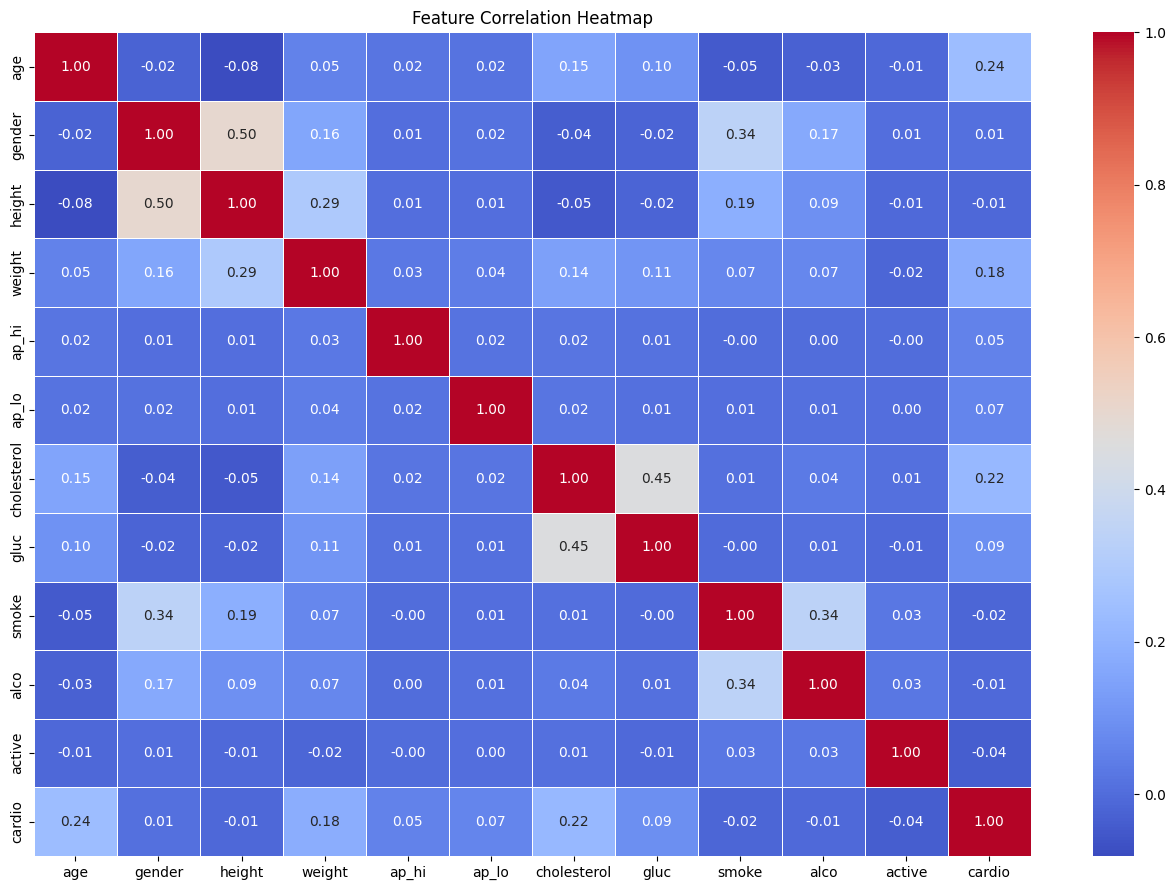

In [79]:
plt.figure(figsize=(13, 9))

correlation = df.drop(columns=["id"]).corr()

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5
)

plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

##Preprocess Part 1

In [80]:
df["age_years"] = df["age"] / 365.25

print(df["age_years"].describe())

count    70000.000000
mean        53.302850
std          6.754967
min         29.563313
25%         48.361396
50%         53.943874
75%         58.390144
max         64.922656
Name: age_years, dtype: float64


In [81]:
# Define candidate conditions
flags = pd.DataFrame(index=df.index)

flags["height_invalid"] = (
    (df["height"] < 120) |
    (df["height"] > 220)
)

flags["weight_invalid"] = (
    (df["weight"] < 30) |
    (df["weight"] > 200)
)

flags["systolic_invalid"] = (
    (df["ap_hi"] < 70) |
    (df["ap_hi"] > 250)
)

flags["diastolic_invalid"] = (
    (df["ap_lo"] < 40) |
    (df["ap_lo"] > 150)
)

flags["bp_relationship_invalid"] = (
    df["ap_hi"] <= df["ap_lo"]
)

# Summary
print("Suspicious measurements by feature:\n")

print(flags.sum())

print("\nRecords with at least one suspicious measurement:")

print(flags.any(axis=1).sum())

print("\nRecords with multiple suspicious measurements:")

print((flags.sum(axis=1) > 1).sum())

Suspicious measurements by feature:

height_invalid               53
weight_invalid                7
systolic_invalid            229
diastolic_invalid          1034
bp_relationship_invalid    1236
dtype: int64

Records with at least one suspicious measurement:
1390

Records with multiple suspicious measurements:
1161


In [82]:
suspicious_records = df.loc[
    flags.any(axis=1),
    [
        "id", "age_years", "gender",
        "height", "weight",
        "ap_hi", "ap_lo",
        "cholesterol", "gluc", "cardio"
    ]
].copy()

display(suspicious_records.head(30))

print("Total suspicious records:", len(suspicious_records))

,id,age_years,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,cardio
224,309,59.685147,2,76,55.0,120,80,1,1,0
228,314,47.882272,2,183,98.0,160,1100,1,2,1
241,334,60.046543,2,157,60.0,160,1000,2,1,1
260,357,49.875428,1,150,83.0,140,800,1,1,1
329,458,64.084873,1,176,63.0,160,1000,2,2,1
345,482,51.208761,1,154,81.0,140,1000,2,1,1
418,594,45.607118,1,157,72.0,150,30,1,1,1
473,680,41.686516,1,150,95.0,150,1033,1,1,1
474,681,52.290212,1,156,65.0,120,150,2,1,0
559,805,55.934292,2,173,101.0,200,1000,1,1,1


Total suspicious records: 1390


In [83]:
# Extremely high or low systolic readings
extreme_systolic = df[
    (df["ap_hi"] < 70) |
    (df["ap_hi"] > 250)
]

# Extremely high or low diastolic readings
extreme_diastolic = df[
    (df["ap_lo"] < 40) |
    (df["ap_lo"] > 150)
]

# Systolic lower than or equal to diastolic
invalid_relationship = df[
    df["ap_hi"] <= df["ap_lo"]
]

print("Extreme systolic readings:", len(extreme_systolic))
print("Extreme diastolic readings:", len(extreme_diastolic))
print("Invalid BP relationship:", len(invalid_relationship))

print("\nExamples of invalid BP relationships:")

display(
    invalid_relationship[
        ["id", "ap_hi", "ap_lo", "cardio"]
    ].head(20)
)

Extreme systolic readings: 229
Extreme diastolic readings: 1034
Invalid BP relationship: 1236

Examples of invalid BP relationships:


,id,ap_hi,ap_lo,cardio
228,314,160,1100,1
241,334,160,1000,1
260,357,140,800,1
329,458,160,1000,1
345,482,140,1000,1
473,680,150,1033,1
474,681,120,150,0
559,805,200,1000,1
567,815,14,90,1
613,886,140,1000,1


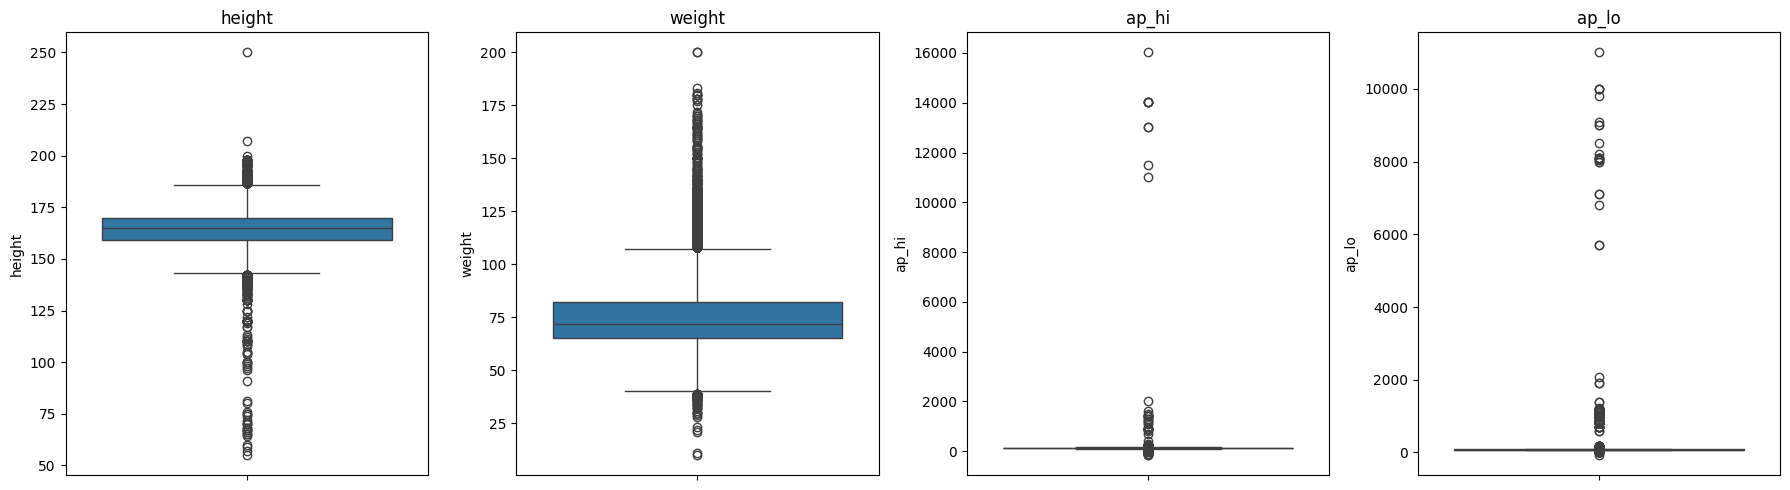

In [84]:
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

features = ["height", "weight", "ap_hi", "ap_lo"]

for feature, ax in zip(features, axes):
    sns.boxplot(y=df[feature], ax=ax)
    ax.set_title(feature)

plt.tight_layout()
plt.show()

##Preprocess Part 2 (Cleanning)

In [85]:
df_work = df.copy()

# Convert age from days to years
df_work["age"] = df_work["age"] / 365.25

print("Age converted successfully!")
print(df_work["age"].describe())

Age converted successfully!
count    70000.000000
mean        53.302850
std          6.754967
min         29.563313
25%         48.361396
50%         53.943874
75%         58.390144
max         64.922656
Name: age, dtype: float64


In [86]:
# Height validation
valid_height = df_work["height"].between(120, 220)

# Weight validation
valid_weight = df_work["weight"].between(30, 200)

# Systolic blood pressure validation
valid_systolic = df_work["ap_hi"].between(70, 250)

# Diastolic blood pressure validation
valid_diastolic = df_work["ap_lo"].between(40, 150)

# Blood pressure relationship
valid_bp_relationship = df_work["ap_hi"] > df_work["ap_lo"]

# Combine all conditions
valid_records = (
    valid_height &
    valid_weight &
    valid_systolic &
    valid_diastolic &
    valid_bp_relationship
)

print("Cleaning rule results:")
print("Invalid height:", (~valid_height).sum())
print("Invalid weight:", (~valid_weight).sum())
print("Invalid systolic BP:", (~valid_systolic).sum())
print("Invalid diastolic BP:", (~valid_diastolic).sum())
print("Invalid BP relationship:", (~valid_bp_relationship).sum())

print("\nTotal records flagged:", (~valid_records).sum())
print("Records retained:", valid_records.sum())

Cleaning rule results:
Invalid height: 53
Invalid weight: 7
Invalid systolic BP: 229
Invalid diastolic BP: 1034
Invalid BP relationship: 1236

Total records flagged: 1390
Records retained: 68610


In [87]:
# Keep only valid records
df_clean = df_work.loc[valid_records].copy()

# Remove patient ID
df_clean.drop(columns=["id"], inplace=True)

# Reset index
df_clean.reset_index(drop=True, inplace=True)

print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)

print("\nRemoved records:", len(df) - len(df_clean))
print("Retained records:", len(df_clean))

Original dataset shape: (70000, 14)
Cleaned dataset shape: (68610, 13)

Removed records: 1390
Retained records: 68610


In [88]:
print("Missing values:")
print(df_clean.isnull().sum().sum())

print("\nDuplicate records:")
print(df_clean.duplicated().sum())

print("\nFeature ranges:")
display(df_clean.describe().T)

print("\nTarget distribution:")
print(df_clean["cardio"].value_counts())

print("\nTarget percentages:")
print(df_clean["cardio"].value_counts(normalize=True) * 100)

Missing values:
0

Duplicate records:
24

Feature ranges:


,count,mean,std,min,25%,50%,75%,max
age,68610.0,53.291488,6.757042,29.563313,48.344969,53.941136,58.38193,64.922656
gender,68610.0,1.348637,0.476542,1.000000,1.000000,1.000000,2.00000,2.000000
height,68610.0,164.413249,7.912820,120.000000,159.000000,165.000000,170.00000,207.000000
weight,68610.0,74.114763,14.296269,30.000000,65.000000,72.000000,82.00000,200.000000
ap_hi,68610.0,126.670821,16.678033,70.000000,120.000000,120.000000,140.00000,240.000000
ap_lo,68610.0,81.301866,9.420957,40.000000,80.000000,80.000000,90.00000,150.000000
cholesterol,68610.0,1.364728,0.678930,1.000000,1.000000,1.000000,2.00000,3.000000
gluc,68610.0,1.225783,0.571638,1.000000,1.000000,1.000000,1.00000,3.000000
smoke,68610.0,0.087976,0.283261,0.000000,0.000000,0.000000,0.00000,1.000000
alco,68610.0,0.053360,0.224751,0.000000,0.000000,0.000000,0.00000,1.000000



Target distribution:
cardio
0    34669
1    33941
Name: count, dtype: int64

Target percentages:
cardio
0    50.530535
1    49.469465
Name: proportion, dtype: float64


In [89]:
assert df_clean["height"].between(120, 220).all()
assert df_clean["weight"].between(30, 200).all()
assert df_clean["ap_hi"].between(70, 250).all()
assert df_clean["ap_lo"].between(40, 150).all()
assert (df_clean["ap_hi"] > df_clean["ap_lo"]).all()

assert df_clean["cardio"].isin([0, 1]).all()

print("All clinical validation checks passed!")

All clinical validation checks passed!


In [90]:
cleaning_summary = pd.DataFrame({
    "Stage": [
        "Original dataset",
        "After clinical cleaning"
    ],
    "Records": [
        len(df),
        len(df_clean)
    ]
})

cleaning_summary["Removed"] = [
    0,
    len(df) - len(df_clean)
]

cleaning_summary["Retention Percentage"] = (
    cleaning_summary["Records"] / len(df) * 100
)

display(cleaning_summary)

,Stage,Records,Removed,Retention Percentage
0,Original dataset,70000,0,100.000000
1,After clinical cleaning,68610,1390,98.014286


##Verifiy Dataset after cleanning

In [91]:
# Start from original data, excluding the previously added age_years
df_work = df.drop(columns=["age_years"], errors="ignore").copy()

# Convert age from days to years
df_work["age"] = df_work["age"] / 365.25

# Define validation rules
valid_records = (
    df_work["height"].between(120, 220) &
    df_work["weight"].between(30, 200) &
    df_work["ap_hi"].between(70, 250) &
    df_work["ap_lo"].between(40, 150) &
    (df_work["ap_hi"] > df_work["ap_lo"])
)

# Create cleaned dataset
df_clean = df_work.loc[valid_records].copy()

# Remove ID
df_clean.drop(columns=["id"], inplace=True)

# Reset index
df_clean.reset_index(drop=True, inplace=True)

print("Original shape:", df.shape)
print("Cleaned shape:", df_clean.shape)

print("\nColumns:")
print(df_clean.columns.tolist())

print("\nExact duplicate rows:", df_clean.duplicated().sum())

Original shape: (70000, 14)
Cleaned shape: (68610, 12)

Columns:
['age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio']

Exact duplicate rows: 24


In [92]:
assert df_clean.shape == (68610, 12)
assert "id" not in df_clean.columns
assert "age_years" not in df_clean.columns
assert df_clean.isnull().sum().sum() == 0

print("Dataset verification passed!")

display(df_clean.describe().T)

Dataset verification passed!


,count,mean,std,min,25%,50%,75%,max
age,68610.0,53.291488,6.757042,29.563313,48.344969,53.941136,58.38193,64.922656
gender,68610.0,1.348637,0.476542,1.000000,1.000000,1.000000,2.00000,2.000000
height,68610.0,164.413249,7.912820,120.000000,159.000000,165.000000,170.00000,207.000000
weight,68610.0,74.114763,14.296269,30.000000,65.000000,72.000000,82.00000,200.000000
ap_hi,68610.0,126.670821,16.678033,70.000000,120.000000,120.000000,140.00000,240.000000
ap_lo,68610.0,81.301866,9.420957,40.000000,80.000000,80.000000,90.00000,150.000000
cholesterol,68610.0,1.364728,0.678930,1.000000,1.000000,1.000000,2.00000,3.000000
gluc,68610.0,1.225783,0.571638,1.000000,1.000000,1.000000,1.00000,3.000000
smoke,68610.0,0.087976,0.283261,0.000000,0.000000,0.000000,0.00000,1.000000
alco,68610.0,0.053360,0.224751,0.000000,0.000000,0.000000,0.00000,1.000000


##Data Splitting

In [93]:
from sklearn.model_selection import StratifiedGroupKFold

# Separate predictors and target
X = df_clean.drop(columns=["cardio"])
y = df_clean["cardio"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nInput features:")
print(X.columns.tolist())

print("\nTarget distribution:")
print(y.value_counts(normalize=True) * 100)

Features shape: (68610, 11)
Target shape: (68610,)

Input features:
['age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active']

Target distribution:
cardio
0    50.530535
1    49.469465
Name: proportion, dtype: float64


In [94]:
# Each unique feature combination receives a group ID
groups = pd.factorize(
    X.apply(tuple, axis=1)
)[0]

print("Total records:", len(X))
print("Unique feature groups:", len(np.unique(groups)))
print("Duplicate records:", len(X) - len(np.unique(groups)))

Total records: 68610
Unique feature groups: 68569
Duplicate records: 41


In [95]:
sgkf_1 = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx, temp_idx = next(
    sgkf_1.split(X, y, groups)
)

X_train = X.iloc[train_idx].copy()
X_temp = X.iloc[temp_idx].copy()

y_train = y.iloc[train_idx].copy()
y_temp = y.iloc[temp_idx].copy()

groups_train = groups[train_idx]
groups_temp = groups[temp_idx]

print("Training set:", X_train.shape)
print("Temporary set:", X_temp.shape)

Training set: (54889, 11)
Temporary set: (13721, 11)


In [96]:
sgkf_2 = StratifiedGroupKFold(
    n_splits=2,
    shuffle=True,
    random_state=42
)

val_idx, test_idx = next(
    sgkf_2.split(X_temp, y_temp, groups_temp)
)

X_val = X_temp.iloc[val_idx].copy()
X_test = X_temp.iloc[test_idx].copy()

y_val = y_temp.iloc[val_idx].copy()
y_test = y_temp.iloc[test_idx].copy()

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Test set:", X_test.shape)

Training set: (54889, 11)
Validation set: (6862, 11)
Test set: (6859, 11)


In [97]:
total = len(df_clean)

splits = {
    "Training": (X_train, y_train),
    "Validation": (X_val, y_val),
    "Test": (X_test, y_test)
}

for name, (features, target) in splits.items():
    print(f"\n{name} Set")
    print("-" * 35)
    print("Records:", len(features))
    print("Percentage:", round(len(features) / total * 100, 2), "%")
    print("Class distribution:")
    print(target.value_counts(normalize=True).sort_index() * 100)


Training Set
-----------------------------------
Records: 54889
Percentage: 80.0 %
Class distribution:
cardio
0    50.394432
1    49.605568
Name: proportion, dtype: float64

Validation Set
-----------------------------------
Records: 6862
Percentage: 10.0 %
Class distribution:
cardio
0    51.267852
1    48.732148
Name: proportion, dtype: float64

Test Set
-----------------------------------
Records: 6859
Percentage: 10.0 %
Class distribution:
cardio
0    50.882053
1    49.117947
Name: proportion, dtype: float64


In [98]:
train_groups = set(groups_train)

val_groups = set(groups_temp[val_idx])
test_groups = set(groups_temp[test_idx])

print("Train-Val overlap:", len(train_groups & val_groups))
print("Train-Test overlap:", len(train_groups & test_groups))
print("Val-Test overlap:", len(val_groups & test_groups))

assert len(train_groups & val_groups) == 0
assert len(train_groups & test_groups) == 0
assert len(val_groups & test_groups) == 0

print("\nNo group leakage detected!")

Train-Val overlap: 0
Train-Test overlap: 0
Val-Test overlap: 0

No group leakage detected!


In [99]:
assert len(X_train) + len(X_val) + len(X_test) == len(df_clean)

assert len(y_train) == len(X_train)
assert len(y_val) == len(X_val)
assert len(y_test) == len(X_test)

print("All splitting checks passed!")

All splitting checks passed!


In [100]:
from sklearn.preprocessing import StandardScaler

continuous_features = [
    "age",
    "height",
    "weight",
    "ap_hi",
    "ap_lo"
]

scaler = StandardScaler()

# Fit ONLY on training data
X_train.loc[:, continuous_features] = scaler.fit_transform(
    X_train[continuous_features]
)

# Transform validation and test using training statistics
X_val.loc[:, continuous_features] = scaler.transform(
    X_val[continuous_features]
)

X_test.loc[:, continuous_features] = scaler.transform(
    X_test[continuous_features]
)

print("Standardization completed!")

Standardization completed!


/tmp/ipykernel_2325/3079796742.py:14: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[ 0.45092185  0.07200031  0.57722902 ...  2.34552951 -0.18061404
  0.7035362 ]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  X_train.loc[:, continuous_features] = scaler.fit_transform(
/tmp/ipykernel_2325/3079796742.py:14: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[-0.99803014  0.19998406  1.39799826 ...  3.19501956  0.49948761
 -0.39902304]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  X_train.loc[:, continuous_features] = scaler.fit_transform(
/tmp/ipykernel_2325/3079796742.py:14: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[-0.13682943 -1.19792441  1.98536055 ...  0.92426556 -0.13682943
 -0.13682

In [101]:
print("Training means:")
display(X_train[continuous_features].mean())

print("\nTraining standard deviations:")
display(X_train[continuous_features].std(ddof=0))

print("\nValidation means:")
display(X_val[continuous_features].mean())

print("\nTest means:")
display(X_test[continuous_features].mean())

Training means:


,0
age,-3.650514e-16
height,-7.207823e-16
weight,-3.482228e-17
ap_hi,3.971552e-16
ap_lo,3.026561e-16



Training standard deviations:


,0
age,1.0
height,1.0
weight,1.0
ap_hi,1.0
ap_lo,1.0



Validation means:


,0
age,0.013340
height,-0.010941
weight,0.009631
ap_hi,0.001182
ap_lo,0.007846



Test means:


,0
age,0.018476
height,-0.010167
weight,0.001730
ap_hi,0.004457
ap_lo,0.005264


In [102]:
# Convert features to NumPy arrays
X_train_np = X_train.to_numpy(dtype=np.float32)
X_val_np = X_val.to_numpy(dtype=np.float32)
X_test_np = X_test.to_numpy(dtype=np.float32)

# Convert targets to integer arrays
y_train_np = y_train.to_numpy(dtype=np.int64)
y_val_np = y_val.to_numpy(dtype=np.int64)
y_test_np = y_test.to_numpy(dtype=np.int64)

# Convert to PyTorch tensors
X_train_tensor = torch.tensor(X_train_np, dtype=torch.float32)
X_val_tensor = torch.tensor(X_val_np, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_np, dtype=torch.float32)

y_train_tensor = torch.tensor(y_train_np, dtype=torch.long)
y_val_tensor = torch.tensor(y_val_np, dtype=torch.long)
y_test_tensor = torch.tensor(y_test_np, dtype=torch.long)

print("Tensor conversion completed!")

print("\nTraining:", X_train_tensor.shape, y_train_tensor.shape)
print("Validation:", X_val_tensor.shape, y_val_tensor.shape)
print("Testing:", X_test_tensor.shape, y_test_tensor.shape)

Tensor conversion completed!

Training: torch.Size([54889, 11]) torch.Size([54889])
Validation: torch.Size([6862, 11]) torch.Size([6862])
Testing: torch.Size([6859, 11]) torch.Size([6859])


In [103]:
# Check whether identical feature sets have conflicting target labels
label_conflicts = (
    df_clean.groupby(X.columns.tolist(), dropna=False)["cardio"]
    .nunique()
)

conflicting_groups = int((label_conflicts > 1).sum())

print("Feature groups with conflicting labels:", conflicting_groups)

Feature groups with conflicting labels: 17


## Intialize Model

In [104]:
class CardiovascularDNN(nn.Module):

    def __init__(self, input_dim=11, dropout=0.3):
        super(CardiovascularDNN, self).__init__()

        self.network = nn.Sequential(

            # First hidden layer
            nn.Linear(input_dim, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(dropout),

            # Second hidden layer
            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(dropout),

            # Third hidden layer
            nn.Linear(64, 32),
            nn.BatchNorm1d(32),
            nn.ReLU(),

            # Output layer
            nn.Linear(32, 2)
        )

    def forward(self, x):
        return self.network(x)

In [105]:
model = CardiovascularDNN(
    input_dim=X_train_tensor.shape[1],
    dropout=0.3
).to(device)

print(model)

print("\nDevice:", device)

total_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print("Trainable parameters:", total_params)

CardiovascularDNN(
  (network): Sequential(
    (0): Linear(in_features=11, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.3, inplace=False)
    (8): Linear(in_features=64, out_features=32, bias=True)
    (9): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): Linear(in_features=32, out_features=2, bias=True)
  )
)

Device: cuda
Trainable parameters: 12386


## Actual Training

In [106]:
# Move all tensors to the selected device (GPU)
X_train_tensor = X_train_tensor.to(device)
y_train_tensor = y_train_tensor.to(device)

X_val_tensor = X_val_tensor.to(device)
y_val_tensor = y_val_tensor.to(device)

X_test_tensor = X_test_tensor.to(device)
y_test_tensor = y_test_tensor.to(device)

# Verify devices
print("Model device:", next(model.parameters()).device)

print("Training features:", X_train_tensor.device)
print("Training labels:", y_train_tensor.device)

print("Validation features:", X_val_tensor.device)
print("Validation labels:", y_val_tensor.device)

print("Test features:", X_test_tensor.device)
print("Test labels:", y_test_tensor.device)

Model device: cuda:0
Training features: cuda:0
Training labels: cuda:0
Validation features: cuda:0
Validation labels: cuda:0
Test features: cuda:0
Test labels: cuda:0


In [107]:
import copy
import time

# Training configuration
LEARNING_RATE = 0.01
EPOCHS = 400

# Loss and optimizer
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

# Training history
history = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": []
}

best_val_loss = float("inf")
best_epoch = 0
best_model_state = None

start_time = time.time()

for epoch in range(EPOCHS):

    # -------------------------
    # Training phase
    # -------------------------
    model.train()

    optimizer.zero_grad()

    train_outputs = model(X_train_tensor)

    train_loss = criterion(
        train_outputs,
        y_train_tensor
    )

    train_loss.backward()
    optimizer.step()

    # -------------------------
    # Evaluation phase
    # -------------------------
    model.eval()

    with torch.no_grad():

        # Training metrics
        train_predictions = model(X_train_tensor)
        train_predicted_classes = torch.argmax(
            train_predictions, dim=1
        )

        train_accuracy = (
            train_predicted_classes == y_train_tensor
        ).float().mean().item()

        # Validation metrics
        val_outputs = model(X_val_tensor)

        val_loss = criterion(
            val_outputs,
            y_val_tensor
        )

        val_predicted_classes = torch.argmax(
            val_outputs, dim=1
        )

        val_accuracy = (
            val_predicted_classes == y_val_tensor
        ).float().mean().item()

    # Store history
    history["train_loss"].append(train_loss.item())
    history["val_loss"].append(val_loss.item())
    history["train_accuracy"].append(train_accuracy)
    history["val_accuracy"].append(val_accuracy)

    # Save best model based on validation loss
    if val_loss.item() < best_val_loss:

        best_val_loss = val_loss.item()
        best_epoch = epoch + 1

        best_model_state = copy.deepcopy(model.state_dict())

    # Print progress
    if (epoch + 1) % 20 == 0 or epoch == 0:

        print(
            f"Epoch [{epoch + 1}/{EPOCHS}] "
            f"Train Loss: {train_loss.item():.4f} | "
            f"Val Loss: {val_loss.item():.4f} | "
            f"Train Acc: {train_accuracy:.4f} | "
            f"Val Acc: {val_accuracy:.4f}"
        )

training_time = time.time() - start_time

# Restore best model
model.load_state_dict(best_model_state)

print("\nTraining completed!")
print(f"Best Epoch: {best_epoch}")
print(f"Best Validation Loss: {best_val_loss:.4f}")
print(f"Training Time: {training_time:.2f} seconds")

Epoch [1/400] Train Loss: 0.7702 | Val Loss: 0.6672 | Train Acc: 0.5479 | Val Acc: 0.5487
Epoch [20/400] Train Loss: 0.5514 | Val Loss: 0.5490 | Train Acc: 0.7333 | Val Acc: 0.7282
Epoch [40/400] Train Loss: 0.5444 | Val Loss: 0.5451 | Train Acc: 0.7362 | Val Acc: 0.7314
Epoch [60/400] Train Loss: 0.5425 | Val Loss: 0.5445 | Train Acc: 0.7367 | Val Acc: 0.7323
Epoch [80/400] Train Loss: 0.5421 | Val Loss: 0.5442 | Train Acc: 0.7372 | Val Acc: 0.7317
Epoch [100/400] Train Loss: 0.5414 | Val Loss: 0.5441 | Train Acc: 0.7379 | Val Acc: 0.7332
Epoch [120/400] Train Loss: 0.5399 | Val Loss: 0.5436 | Train Acc: 0.7388 | Val Acc: 0.7323
Epoch [140/400] Train Loss: 0.5388 | Val Loss: 0.5435 | Train Acc: 0.7394 | Val Acc: 0.7336
Epoch [160/400] Train Loss: 0.5396 | Val Loss: 0.5438 | Train Acc: 0.7397 | Val Acc: 0.7335
Epoch [180/400] Train Loss: 0.5378 | Val Loss: 0.5438 | Train Acc: 0.7400 | Val Acc: 0.7321
Epoch [200/400] Train Loss: 0.5375 | Val Loss: 0.5443 | Train Acc: 0.7405 | Val Acc: 0

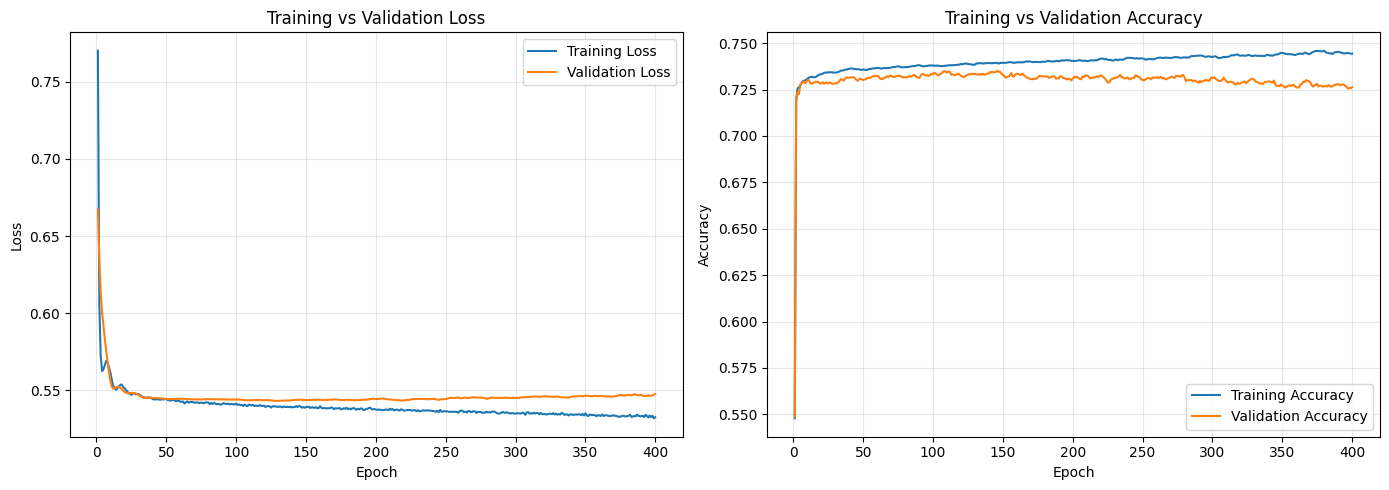

In [108]:
epochs_range = range(1, EPOCHS + 1)

plt.figure(figsize=(14, 5))

# Loss plot
plt.subplot(1, 2, 1)

plt.plot(
    epochs_range,
    history["train_loss"],
    label="Training Loss"
)

plt.plot(
    epochs_range,
    history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(alpha=0.3)

# Accuracy plot
plt.subplot(1, 2, 2)

plt.plot(
    epochs_range,
    history["train_accuracy"],
    label="Training Accuracy"
)

plt.plot(
    epochs_range,
    history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [109]:
torch.save(
    {
        "model_state_dict": model.state_dict(),
        "best_epoch": best_epoch,
        "best_val_loss": best_val_loss,
        "input_dim": 11,
        "dropout": 0.3
    },
    "best_cardiovascular_dnn.pth"
)

print("Best model saved successfully!")

Best model saved successfully!


## Evaluatio part 1 (Validation set)

In [110]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

# Make sure we use the best model
model.eval()

with torch.no_grad():

    val_outputs = model(X_val_tensor)

    # Predicted classes
    val_predictions = torch.argmax(val_outputs, dim=1)

    # Probability of class 1
    val_probabilities = torch.softmax(
        val_outputs, dim=1
    )[:, 1]

# Move predictions and labels to CPU
y_val_true = y_val_tensor.cpu().numpy()
y_val_pred = val_predictions.cpu().numpy()
y_val_prob = val_probabilities.cpu().numpy()

# Calculate metrics
val_accuracy = accuracy_score(y_val_true, y_val_pred)

val_precision = precision_score(
    y_val_true, y_val_pred, zero_division=0
)

val_recall = recall_score(
    y_val_true, y_val_pred, zero_division=0
)

val_f1 = f1_score(
    y_val_true, y_val_pred, zero_division=0
)

val_auc = roc_auc_score(y_val_true, y_val_prob)

print("Validation Results")
print("------------------------------")
print(f"Accuracy:  {val_accuracy:.4f}")
print(f"Precision: {val_precision:.4f}")
print(f"Recall:    {val_recall:.4f}")
print(f"F1-score:  {val_f1:.4f}")
print(f"ROC-AUC:   {val_auc:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_val_true,
        y_val_pred,
        target_names=["No Disease (0)", "Disease (1)"],
        zero_division=0
    )
)

Validation Results
------------------------------
Accuracy:  0.7335
Precision: 0.7491
Recall:    0.6812
F1-score:  0.7135
ROC-AUC:   0.8004

Classification Report:
                precision    recall  f1-score   support

No Disease (0)       0.72      0.78      0.75      3518
   Disease (1)       0.75      0.68      0.71      3344

      accuracy                           0.73      6862
     macro avg       0.74      0.73      0.73      6862
  weighted avg       0.73      0.73      0.73      6862



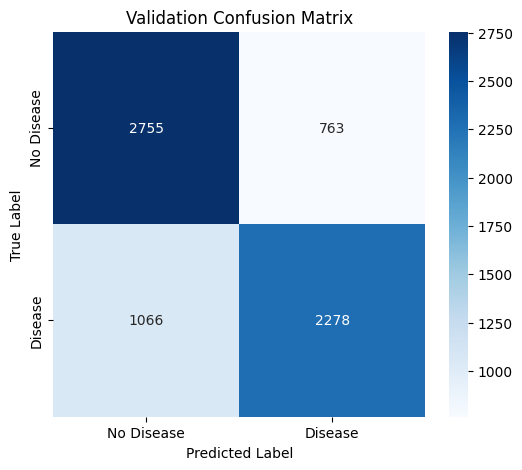

In [111]:
cm = confusion_matrix(y_val_true, y_val_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Disease", "Disease"],
    yticklabels=["No Disease", "Disease"]
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Validation Confusion Matrix")

plt.show()

##Tune Hyperprameters

In [112]:
import copy
import itertools
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim

learning_rates = [0.001, 0.005, 0.01]
weight_decays = [0, 0.0001]

MAX_EPOCHS = 400
PATIENCE = 30

tuning_results = []

global_best_val_loss = float("inf")
global_best_state = None
global_best_config = None

for lr, wd in itertools.product(learning_rates, weight_decays):

    print(f"\nTesting LR={lr}, Weight Decay={wd}")

    # Reset seed to make initialization comparable
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    candidate_model = CardiovascularDNN(
        input_dim=11,
        dropout=0.3
    ).to(device)

    criterion = nn.CrossEntropyLoss()

    optimizer = optim.Adam(
        candidate_model.parameters(),
        lr=lr,
        weight_decay=wd
    )

    best_config_loss = float("inf")
    best_config_epoch = 0
    best_config_state = None
    patience_counter = 0

    for epoch in range(MAX_EPOCHS):

        # Training
        candidate_model.train()

        optimizer.zero_grad()

        train_outputs = candidate_model(X_train_tensor)
        train_loss = criterion(train_outputs, y_train_tensor)

        train_loss.backward()
        optimizer.step()

        # Validation
        candidate_model.eval()

        with torch.no_grad():
            val_outputs = candidate_model(X_val_tensor)

            val_loss = criterion(
                val_outputs,
                y_val_tensor
            ).item()

        # Save best checkpoint for this configuration
        if val_loss < best_config_loss:

            best_config_loss = val_loss
            best_config_epoch = epoch + 1

            best_config_state = copy.deepcopy(
                candidate_model.state_dict()
            )

            patience_counter = 0

        else:
            patience_counter += 1

        # Early stopping
        if patience_counter >= PATIENCE:
            break

    tuning_results.append({
        "learning_rate": lr,
        "weight_decay": wd,
        "best_epoch": best_config_epoch,
        "best_val_loss": best_config_loss
    })

    print(
        f"Best Epoch: {best_config_epoch} | "
        f"Best Val Loss: {best_config_loss:.4f}"
    )

    # Update global best configuration
    if best_config_loss < global_best_val_loss:

        global_best_val_loss = best_config_loss

        global_best_state = copy.deepcopy(
            best_config_state
        )

        global_best_config = {
            "learning_rate": lr,
            "weight_decay": wd,
            "best_epoch": best_config_epoch
        }

    del candidate_model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# Display results
tuning_df = pd.DataFrame(tuning_results)

tuning_df = tuning_df.sort_values(
    by="best_val_loss"
).reset_index(drop=True)

print("\nHyperparameter Tuning Results:")
display(tuning_df)

print("\nBest Configuration:")
print(global_best_config)
print(f"Best Validation Loss: {global_best_val_loss:.4f}")


Testing LR=0.001, Weight Decay=0
Best Epoch: 247 | Best Val Loss: 0.5445

Testing LR=0.001, Weight Decay=0.0001
Best Epoch: 247 | Best Val Loss: 0.5445

Testing LR=0.005, Weight Decay=0
Best Epoch: 138 | Best Val Loss: 0.5440

Testing LR=0.005, Weight Decay=0.0001
Best Epoch: 111 | Best Val Loss: 0.5448

Testing LR=0.01, Weight Decay=0
Best Epoch: 128 | Best Val Loss: 0.5431

Testing LR=0.01, Weight Decay=0.0001
Best Epoch: 49 | Best Val Loss: 0.5454

Hyperparameter Tuning Results:


,learning_rate,weight_decay,best_epoch,best_val_loss
0,0.010,0.0000,128,0.543087
1,0.005,0.0000,138,0.543958
2,0.001,0.0000,247,0.544486
3,0.001,0.0001,247,0.544516
4,0.005,0.0001,111,0.544846
5,0.010,0.0001,49,0.545366



Best Configuration:
{'learning_rate': 0.01, 'weight_decay': 0, 'best_epoch': 128}
Best Validation Loss: 0.5431


In [113]:
model = CardiovascularDNN(
    input_dim=11,
    dropout=0.3
).to(device)

model.load_state_dict(global_best_state)
model.eval()

print("Best tuned model loaded successfully!")
print("Configuration:", global_best_config)

Best tuned model loaded successfully!
Configuration: {'learning_rate': 0.01, 'weight_decay': 0, 'best_epoch': 128}


In [114]:
torch.save({
    "model_state_dict": model.state_dict(),
    "best_config": global_best_config,
    "best_val_loss": global_best_val_loss,
    "input_dim": 11,
    "dropout": 0.3
}, "best_tuned_cardiovascular_dnn.pth")

print("Tuned model saved successfully!")

Tuned model saved successfully!


## Baseline (Shallow MLP)

In [115]:
#================
# Baseline Model Architecture
#================

class CardiovascularShallowMLP(nn.Module):

    def __init__(self, input_dim):
        super(CardiovascularShallowMLP, self).__init__()

        self.network = nn.Sequential(
            nn.Linear(input_dim, 32),
            nn.ReLU(),
            nn.Linear(32, 2)
        )

    def forward(self, x):
        return self.network(x)


baseline_model = CardiovascularShallowMLP(
    input_dim=X_train_tensor.shape[1]
).to(device)

print(baseline_model)

baseline_params = sum(
    p.numel()
    for p in baseline_model.parameters()
    if p.requires_grad
)

deep_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("\nTrainable Parameters:")
print("Baseline MLP:", baseline_params)
print("Deep MLP:", deep_params)

CardiovascularShallowMLP(
  (network): Sequential(
    (0): Linear(in_features=11, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=2, bias=True)
  )
)

Trainable Parameters:
Baseline MLP: 450
Deep MLP: 12386


In [116]:

#================
# Baseline Model Training & Tuning
#================

baseline_best_train_history = None
baseline_best_val_history = None

learning_rates = [0.001, 0.005, 0.01]
weight_decays = [0, 0.0001]

MAX_EPOCHS = 400
PATIENCE = 30

baseline_tuning_results = []

baseline_best_val_loss = float("inf")
baseline_best_state = None
baseline_best_config = None

criterion = nn.CrossEntropyLoss()

for lr, wd in itertools.product(learning_rates, weight_decays):

    print(f"\nTesting LR={lr}, Weight Decay={wd}")

    # Reset seed for comparable initialization
    torch.manual_seed(SEED)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    candidate_model = CardiovascularShallowMLP(
        input_dim=X_train_tensor.shape[1]
    ).to(device)

    optimizer = optim.Adam(
        candidate_model.parameters(),
        lr=lr,
        weight_decay=wd
    )

    best_config_loss = float("inf")
    best_config_epoch = 0
    best_config_state = None

    # Track loss for this configuration
    train_history = []
    val_history = []

    patience_counter = 0

    for epoch in range(MAX_EPOCHS):

        # Training
        candidate_model.train()

        optimizer.zero_grad()

        train_outputs = candidate_model(X_train_tensor)

        train_loss = criterion(
            train_outputs,
            y_train_tensor
        )

        train_loss.backward()
        optimizer.step()

        # Validation
        candidate_model.eval()

        with torch.no_grad():

            val_outputs = candidate_model(X_val_tensor)

            val_loss = criterion(
                val_outputs,
                y_val_tensor
            ).item()

        # Record epoch losses
        train_history.append(train_loss.item())
        val_history.append(val_loss)

        # Save best checkpoint
        if val_loss < best_config_loss:

            best_config_loss = val_loss
            best_config_epoch = epoch + 1

            best_config_state = copy.deepcopy(
                candidate_model.state_dict()
            )

            patience_counter = 0

        else:
            patience_counter += 1

        # Early stopping
        if patience_counter >= PATIENCE:
            break

    baseline_tuning_results.append({
        "learning_rate": lr,
        "weight_decay": wd,
        "best_epoch": best_config_epoch,
        "best_val_loss": best_config_loss
    })

    print(
        f"Best Epoch: {best_config_epoch} | "
        f"Best Val Loss: {best_config_loss:.4f}"
    )

    # Keep the best configuration and its histories
    if best_config_loss < baseline_best_val_loss:

        baseline_best_val_loss = best_config_loss

        baseline_best_state = copy.deepcopy(
            best_config_state
        )

        baseline_best_train_history = train_history.copy()
        baseline_best_val_history = val_history.copy()

        baseline_best_config = {
            "learning_rate": lr,
            "weight_decay": wd,
            "best_epoch": best_config_epoch
        }

    del candidate_model

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# Display tuning results
baseline_tuning_df = pd.DataFrame(
    baseline_tuning_results
).sort_values(
    by="best_val_loss"
).reset_index(drop=True)

print("\nBaseline Tuning Results:")
display(baseline_tuning_df)

print("\nBest Baseline Configuration:")
print(baseline_best_config)

print(f"Best Validation Loss: {baseline_best_val_loss:.4f}")



Testing LR=0.001, Weight Decay=0
Best Epoch: 400 | Best Val Loss: 0.5525

Testing LR=0.001, Weight Decay=0.0001
Best Epoch: 400 | Best Val Loss: 0.5520

Testing LR=0.005, Weight Decay=0
Best Epoch: 326 | Best Val Loss: 0.5457

Testing LR=0.005, Weight Decay=0.0001
Best Epoch: 334 | Best Val Loss: 0.5451

Testing LR=0.01, Weight Decay=0
Best Epoch: 394 | Best Val Loss: 0.5443

Testing LR=0.01, Weight Decay=0.0001
Best Epoch: 214 | Best Val Loss: 0.5444

Baseline Tuning Results:


,learning_rate,weight_decay,best_epoch,best_val_loss
0,0.010,0.0000,394,0.544263
1,0.010,0.0001,214,0.544447
2,0.005,0.0001,334,0.545121
3,0.005,0.0000,326,0.545688
4,0.001,0.0001,400,0.551973
5,0.001,0.0000,400,0.552505



Best Baseline Configuration:
{'learning_rate': 0.01, 'weight_decay': 0, 'best_epoch': 394}
Best Validation Loss: 0.5443


In [117]:
#================
# Load Best Baseline Model
#================

baseline_model = CardiovascularShallowMLP(
    input_dim=X_train_tensor.shape[1]
).to(device)

baseline_model.load_state_dict(baseline_best_state)

baseline_model.eval()

print("Best baseline model loaded successfully!")
print("Configuration:", baseline_best_config)

Best baseline model loaded successfully!
Configuration: {'learning_rate': 0.01, 'weight_decay': 0, 'best_epoch': 394}


## Evaluation

In [118]:
#================
# Final Test Evaluation — Model Comparison
#================

model.eval()
baseline_model.eval()

with torch.no_grad():

    # Deep MLP
    deep_outputs = model(X_test_tensor)

    deep_probabilities = torch.softmax(
        deep_outputs, dim=1
    )[:, 1]

    deep_predictions = torch.argmax(
        deep_outputs, dim=1
    )

    # Shallow MLP baseline
    baseline_outputs = baseline_model(X_test_tensor)

    baseline_probabilities = torch.softmax(
        baseline_outputs, dim=1
    )[:, 1]

    baseline_predictions = torch.argmax(
        baseline_outputs, dim=1
    )


# Convert to NumPy
y_test_true = y_test_tensor.cpu().numpy()

deep_pred = deep_predictions.cpu().numpy()
deep_prob = deep_probabilities.cpu().numpy()

baseline_pred = baseline_predictions.cpu().numpy()
baseline_prob = baseline_probabilities.cpu().numpy()


# Calculate metrics
def calculate_metrics(y_true, y_pred, y_prob):

    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_true, y_prob)
    }


deep_test_metrics = calculate_metrics(
    y_test_true, deep_pred, deep_prob
)

baseline_test_metrics = calculate_metrics(
    y_test_true, baseline_pred, baseline_prob
)


# Comparison table
comparison = pd.DataFrame({
    "Metric": list(deep_test_metrics.keys()),
    "Shallow MLP Baseline": list(baseline_test_metrics.values()),
    "Deep MLP": list(deep_test_metrics.values())
})

comparison["Difference"] = (
    comparison["Deep MLP"] -
    comparison["Shallow MLP Baseline"]
)

print("FINAL TEST RESULTS")
print("=" * 55)

display(comparison.round(4))

FINAL TEST RESULTS


,Metric,Shallow MLP Baseline,Deep MLP,Difference
0,Accuracy,0.7367,0.7390,0.0023
1,Precision,0.7551,0.7566,0.0014
2,Recall,0.6866,0.6910,0.0045
3,F1-score,0.7192,0.7223,0.0031
4,ROC-AUC,0.8032,0.8035,0.0003


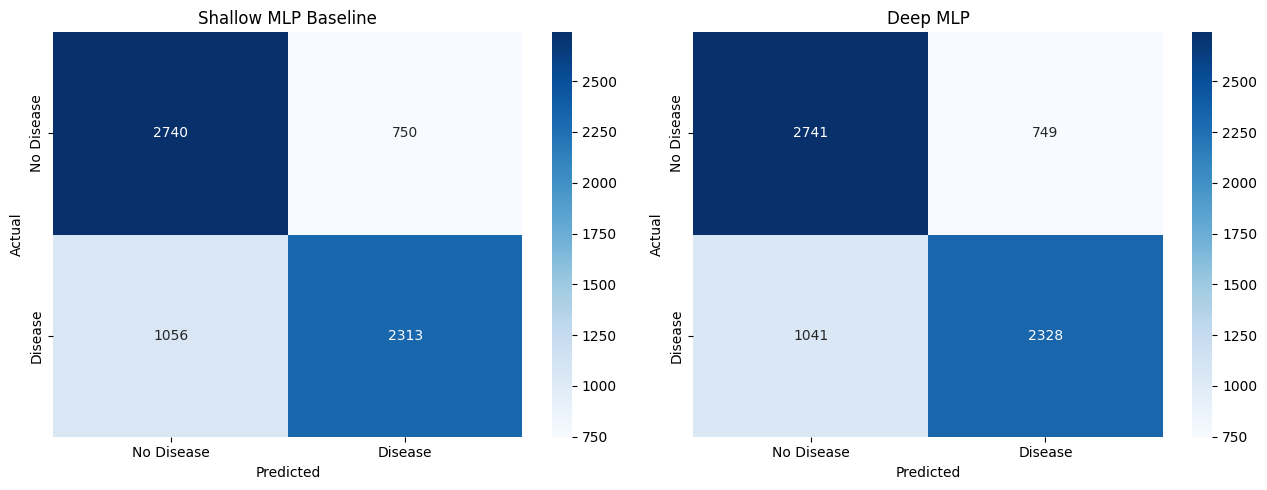

In [119]:
#================
# Confusion Matrix Comparison
#================

baseline_cm = confusion_matrix(
    y_test_true, baseline_pred
)

deep_cm = confusion_matrix(
    y_test_true, deep_pred
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.heatmap(
    baseline_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Disease", "Disease"],
    yticklabels=["No Disease", "Disease"],
    ax=axes[0]
)

axes[0].set_title("Shallow MLP Baseline")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(
    deep_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Disease", "Disease"],
    yticklabels=["No Disease", "Disease"],
    ax=axes[1]
)

axes[1].set_title("Deep MLP")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

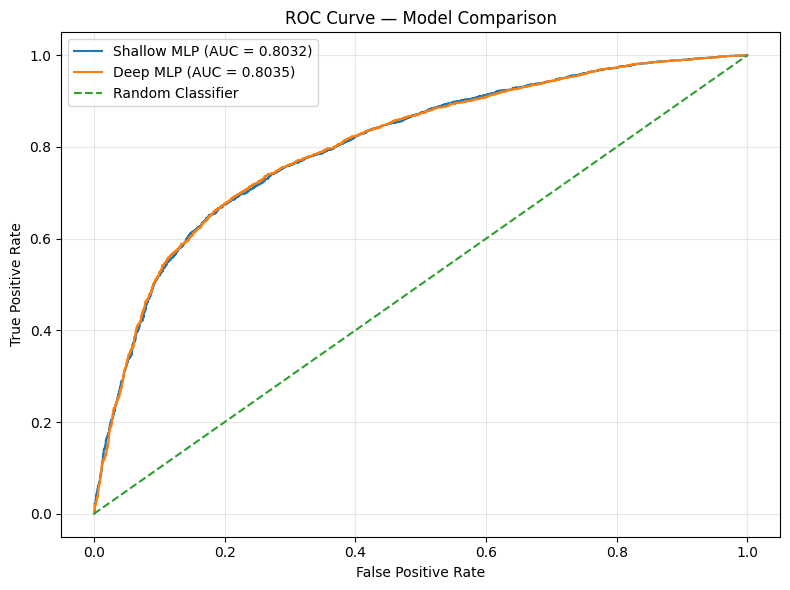

In [120]:
#================
# ROC Curve Comparison
#================

baseline_fpr, baseline_tpr, _ = roc_curve(
    y_test_true, baseline_prob
)

deep_fpr, deep_tpr, _ = roc_curve(
    y_test_true, deep_prob
)

baseline_auc = roc_auc_score(
    y_test_true, baseline_prob
)

deep_auc = roc_auc_score(
    y_test_true, deep_prob
)

plt.figure(figsize=(8, 6))

plt.plot(
    baseline_fpr,
    baseline_tpr,
    label=f"Shallow MLP (AUC = {baseline_auc:.4f})"
)

plt.plot(
    deep_fpr,
    deep_tpr,
    label=f"Deep MLP (AUC = {deep_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Model Comparison")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()